## **Our Dataset (From Kaggle)**

In [121]:
import pandas as pd
df = pd.read_csv("data/ousssama_dataset_backup_copy.zip")

## Phase 1: Exploratory Data Analysis (EDA)

Here we will start exploring our data to understand the features and see how the dataset looks.

In [122]:
df.head(10)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
5,6,0,Graduate,Yes,4800000,13500000,10,319,6800000,8300000,13700000,5100000,Rejected
6,7,5,Graduate,No,8700000,33000000,4,678,22500000,14800000,29200000,4300000,Approved
7,8,2,Graduate,Yes,5700000,15000000,20,382,13200000,5700000,11800000,6000000,Rejected
8,9,0,Graduate,Yes,800000,2200000,20,782,1300000,800000,2800000,600000,Approved
9,10,5,Not Graduate,No,1100000,4300000,10,388,3200000,1400000,3300000,1600000,Rejected


This dataset is from India. We thought about converting the values into dollars, but the financial ecosystem is completely different. For example, $50,000 is an average annual income in the US, but in India, it is a huge amount. This directly affects the probability of loan approval. Therefore, We decided to keep the original values in the Indian currency (INR - ₹) to keep the model realistic.

**Here is what each column means and its role in the loan decision:**

* no_of_dependents: The number of family members supported by the applicant. More dependents mean higher monthly expenses, which can affect the ability to repay the loan.

* education: Shows if the applicant is a Graduate or Not. Usually, graduates have better career stability and steady income.

* self_employed: Shows if the person works for a company or runs their own business. Banks check this because freelance or business income can change from month to month compared to a fixed salary.

* income_annum: The total yearly income. This is the main factor banks use to see how big of a loan the person can actually afford.

* loan_amount: The amount of money the applicant is asking to borrow.

* loan_term: The period (in months) to pay back the loan. A shorter term means the applicant has to pay larger monthly installments to clear the debt quickly, which might put more pressure on their monthly budget.

* cibil_score: The credit score (between 300 and 900). This is the most critical feature because it shows the person's financial history and how trusted they are with paying back debts.

* residential_assets_value, commercial_assets_value, luxury_assets_value, bank_asset_value: These represent the applicant's property and savings. If the borrower stops paying, the bank can use these assets as collateral to get their money back.

* loan_status: Our target variable (Approved or Rejected) which the model will predict.

* loan_id: This is just a unique serial number given to each loan application. It does not contain any real information about the customer's financial behavior, so it is not important for training. That's why i will delete it.

In [123]:
df = df.drop(columns=['loan_id'])

First, we will check whether there are any missing values in our dataset before starting the analysis.

In [124]:
df.isnull().sum()

no_of_dependents             0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

In [125]:
df.dtypes

no_of_dependents              int64
 education                   object
 self_employed               object
 income_annum                 int64
 loan_amount                  int64
 loan_term                    int64
 cibil_score                  int64
 residential_assets_value     int64
 commercial_assets_value      int64
 luxury_assets_value          int64
 bank_asset_value             int64
 loan_status                 object
dtype: object

Since there is no missing data, we will clean the column names and text values by converting them to lowercase and replacing spaces with underscores. This makes the data uniform and easier to work with.

In [126]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)
for c in categorical_columns:
    df[c] = df[c].str.strip().str.lower().str.replace(' ', '_')


In [127]:
df['_self_employed'].value_counts()

_self_employed
yes    2150
no     2119
Name: count, dtype: int64

In [128]:
df['_education'].value_counts()

_education
graduate        2144
not_graduate    2125
Name: count, dtype: int64

In [129]:
df['_loan_status'].value_counts()

_loan_status
approved    2656
rejected    1613
Name: count, dtype: int64

Since these categorical columns have only two unique values, we will convert them into binary numbers (0 and 1). This is simple encoding so the machine learning model can understand the data without adding extra columns.

In [130]:
df._self_employed = (df._self_employed == 'yes').astype(int)
df._education = (df._education == 'graduate').astype(int)
df._loan_status = (df._loan_status == 'approved').astype(int)

## Dataset Splitting:

Now we will split the dataset into three parts: Train (60%), Validation (20%), and Test (20%).

1. Train set: The biggest slice, used to let the models learn the patterns

2. Validation set: Used to tune the hyperparameters and select the best model

3. Test set: Kept completely separate to evaluate the final performance on unseen data.

We also delete the target variable (_loan_status) from the feature matrices and save it separately as y variables so the model doesn't see the answers during training.

In [131]:
from sklearn.model_selection import train_test_split

In [132]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train._loan_status.values
y_val = df_val._loan_status.values
y_test = df_test._loan_status.values

del df_train['_loan_status']
del df_val['_loan_status']
del df_test['_loan_status']

## Feature Extraction & Encoding:

Since all the classification models will use the same feature transformation, we define the DictVectorizer once here. We convert our DataFrames into dictionaries first, then apply the vectorizer to prepare the features for training.

In [133]:
from sklearn.feature_extraction import DictVectorizer

In [134]:
dicts = df_train.to_dict(orient='records')
dictss = df_val.to_dict(orient='records')
dictsss = df_test.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(dicts)
X_val = dv.transform(dictss)
X_test = dv.transform(dictsss)


## **Training the classification models:**

## 1. Baseline Model: Logistic Regression

Logistic Regression serves as our baseline model. It is highly efficient and the easiest to tune, primarily because its performance is governed by a single key hyperparameter: **C** (the inverse of regularization strength).

### Hyperparameter Tuning (C-values)
To find the best configuration, we evaluate the model across a list of **C** values, calculating the **ROC-AUC score** for each. By comparing the results, we select the specific parameter value that maximizes the **ROC-AUC score**.

In [135]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [136]:
for C in [0.001, 0.01, 0.1, 0.5, 1, 5, 10, 100]:
    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train, y_train)
    y_pred = model.predict_proba(X_train)[:, 1]
    auc = roc_auc_score(y_train, y_pred)
    print(auc)
    

0.8824071573657699
0.88099039970569
0.8808175448346399
0.8808031946189299
0.8808031946189301
0.8808018900538654
0.8808018900538654
0.8956054421236231


In [137]:
model_logistic = LogisticRegression(C=100, max_iter=1000)
model_logistic.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,100
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


## 2. Decision Tree Classifier

Since we have two hyperparameters to tune (max_depth and min_samples_leaf), we will use a heatmap. This helps us find the best combination of both parameters together, because sometimes individual best values don't give the highest overall **AUC** score when combined.

In [138]:
from sklearn.tree import DecisionTreeClassifier
import seaborn as sns

In [139]:
scores = []

for d in [4, 5, 6, 7, 10, 15, 20, None]:
    for s in [1, 2, 5, 10, 15, 20, 100, 200, 500]:
        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=s)
        dt.fit(X_train, y_train)
        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((d, s, auc))

<Axes: xlabel='max_depth', ylabel='min_samples_leaf'>

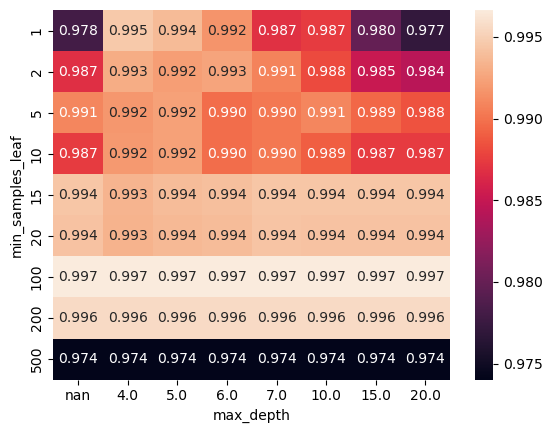

In [140]:
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores.sort_values(by='auc', ascending=False)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns='max_depth', values='auc')

sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

As we can see from the heatmap, the AUC scores are extremely high across almost all combinations. This might look like data leakage  . I will not analyze this deeply right now, **but i am keeping an eye on it.**

In [141]:
model_dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=100)
model_dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,100
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


## 3. Random Forest Classifier

Since we have three hyperparameters to tune (max_depth, min_samples_leaf, and n_estimators), a standard 2D heatmap won't work unless we can magically build a 3D heatmap cube.

To keep it clean and efficient, we will break the tuning down into two sequential steps using line plots:


1. First, we tune different values of max_depth across a range of n_estimators to find the most stable depth.


2. Once the best max_depth is selected, the final role goes to the number of trees (n_estimators). We will plot different curves of min_samples_leaf against the number of trees.

This allows us to track the exact number of trees that preserves the highest overall AUC score for our best chosen depth and leaf parameters simultaneously.

In [142]:
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

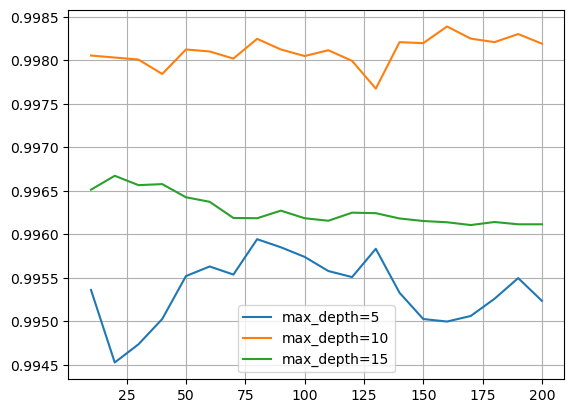

In [143]:
scores = []
for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=1)
        rf.fit(X_train, y_train)
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((d, n, auc))

columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]
    plt.plot(df_subset.n_estimators, df_subset.auc, label=f'max_depth={d}')
plt.legend()
plt.grid(True)

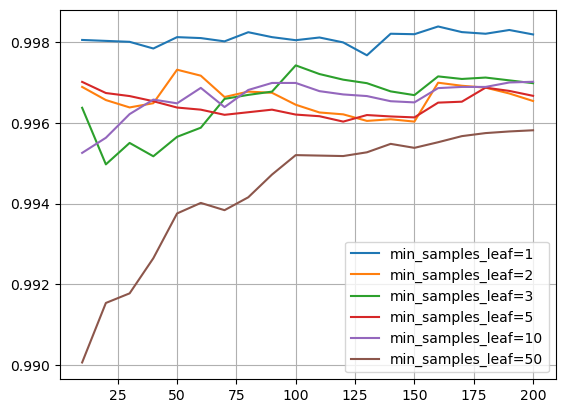

In [144]:
scores = []
for s in [1, 2, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=10, min_samples_leaf=s, random_state=1)
        rf.fit(X_train, y_train)
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((s, n, auc))



columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)


for s in [1, 2, 3, 5, 10, 50]:
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    plt.plot(df_subset.n_estimators, df_subset.auc, label=f'min_samples_leaf={s}')
plt.legend()
plt.grid(True)


Based on the plots, we selected n_estimators=175, max_depth=10, and min_samples_leaf=1 as our final parameters.

Once again, we notice that the final validation AUC is extremely high (nearly 0.998). This confirms our earlier suspicion about data behavior or potential leakage, which we will analyze and explain in detail after testing all our models.

In [145]:
model_rfc = RandomForestClassifier(n_estimators=175, max_depth=10, min_samples_leaf=1, random_state=1)
model_rfc.fit(X_train, y_train)

,n_estimators,175
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## 4. XGBoost Classifier

Tuning XGBoost can be expensive because it has multiple hyperparameters. To be efficient and avoid crashing our system, we will use a step-by-step approach:


1. First, we fix the learning rate and the number of trees. Then, we use a 2D heatmap to find the best combination for max_depth and min_child_weight.



2. Second, once we find the best structural parameters, we will optimize the learning rate (eta) and the number of trees individually using line plots.

In [146]:
import xgboost as xgb

In [147]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

<Axes: xlabel='max_depth', ylabel='min_child_weight'>

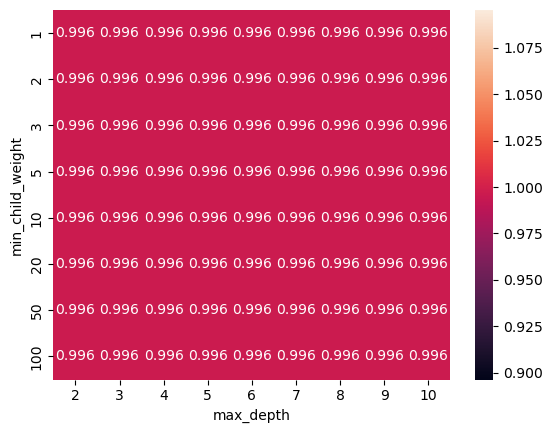

In [148]:
e = 0.1
xgb_scores = []

for w in [1, 2, 3, 5, 10, 20, 50, 100]:
    for d in [2, 3, 4, 5, 6, 7, 8, 9, 10]:
        xgb_params = {
            'eta': e,
            'max_depth': d,
            'min_child_weight': w,
            'objective': 'binary:logistic', 
            'seed': 1,
        }
        xgb_model = xgb.train(xgb_params, dtrain, num_boost_round=175,)
        y_pred = xgb_model.predict(dval)
        roc_auc_score(y_val, y_pred)
        xgb_scores.append((w, d, auc))

columns = ['min_child_weight', 'max_depth', 'auc']
df_scores = pd.DataFrame(xgb_scores, columns=columns)
df_scores.sort_values(by='auc', ascending=False)


df_scores_pivot = df_scores.pivot(index='min_child_weight', columns='max_depth', values='auc')


sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

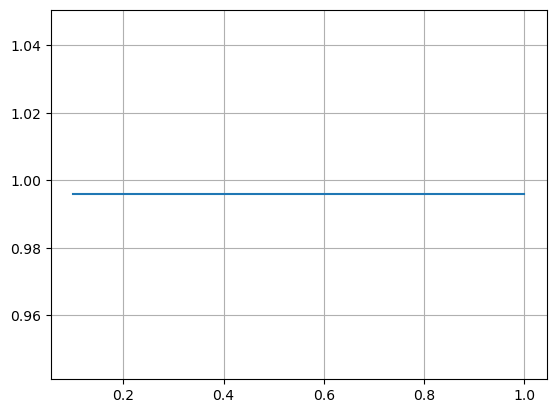

In [149]:
xgb2_scores = []


for e in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]:
    xgb_params = {
            'eta': e,
            'max_depth': 5,
            'min_child_weight': 1,
            'objective': 'binary:logistic', 
            'seed': 1,
            'eval_metric': 'auc',
    }
    xgb_model = xgb.train(xgb_params, dtrain, num_boost_round=175)
    y_pred = xgb_model.predict(dval)
    roc_auc_score(y_val, y_pred)
    xgb2_scores.append((e, auc))

    columns = ['eta', 'auc']
df_scores = pd.DataFrame(xgb2_scores, columns=columns)
df_scores.sort_values(by='auc', ascending=False)

plt.plot(df_scores.eta, df_scores.auc)
plt.grid(True)

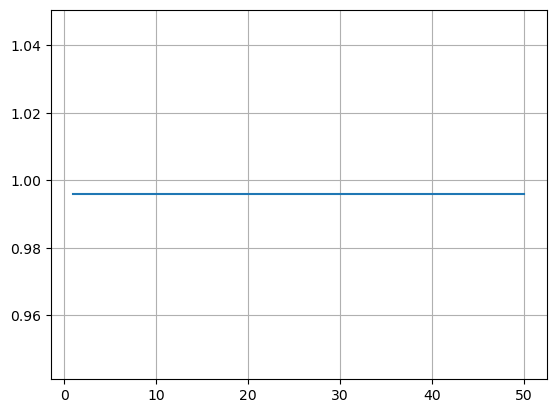

In [150]:
lists = []

for n in[1, 2, 3, 4, 5, 10, 25, 50]:

    xgb_params = {
            'eta': 0.2,
            'max_depth': 5,
            'min_child_weight': 1,
            'objective': 'binary:logistic', 
            'seed': 1,
            'eval_metric': 'auc',
    }
    xgb_model = xgb.train(xgb_params, dtrain, num_boost_round=n)
    y_pred = xgb_model.predict(dval)
    roc_auc_score(y_val, y_pred)
    lists.append((n, auc))


columns = ['n', 'auc']
df_scores = pd.DataFrame(lists, columns=columns)
df_scores.sort_values(by='auc', ascending=False)

plt.plot(df_scores.n, df_scores.auc)
plt.grid(True)


For the final model training, we switched to the Scikit-Learn wrapper API (XGBClassifier) and used the standard .fit() method.

This is important because later, we will put all our trained models inside a single for loop to calculate and compare their validation AUC scores. Having the same .fit() function allows the loop to work smoothly across every model in our list.

In [151]:
from xgboost import XGBClassifier
from xgboost import XGBRegressor


xgb_model_class = XGBClassifier(
    n_estimators=100,
    learning_rate=0.2,
    max_depth=5,
    min_child_weight=1,
    objective='binary:logistic', 
    random_state=1
)
xgb_model_class.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


## Investigating the High AUC

As we can see, the AUC score is almost 1.0 across all models. The heatmap is completely red, and the lines on our tuning plots are nearly perfect.

To understand why our models are performing this perfectly, we need to analyze our data behavior. Right below, we will check whether Feature Importance is the reason driving these extreme results.


In [152]:

importances = model_dt.feature_importances_
feature_names = dv.get_feature_names_out()

df_importance = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
print(df_importance.sort_values(by='Importance', ascending=False).head(5))

                     Feature  Importance
1               _cibil_score    0.913001
6                 _loan_term    0.084630
5               _loan_amount    0.001777
8  _residential_assets_value    0.000592
0          _bank_asset_value    0.000000


## Feature Importance Analysis: The Secret Revealed

Here is the key: the _cibil_score feature holds 91% of the model's total importance! This massive signal makes the classification so easy that even a simple rule-based system could achieve **over 90% AUC**.

To test our theory and see whether the problem is just this single important feature or something else like data leakage, we will drop this column and retrain the model. If the AUC decreases, then it confirms the high score was purely because of this feature's high importance. If the AUC stays high, it means there is **another reason**.

In [153]:
df_cilib_train = df_train.drop(columns=['_cibil_score'])
df_cilib_val = df_val.drop(columns=['_cibil_score'])

dvv = DictVectorizer(sparse=False)

dict1 = df_cilib_train.to_dict(orient='records')
dict2 = df_cilib_val.to_dict(orient='records')

Xi_train = dvv.fit_transform(dict1)
Xi_val = dvv.transform(dict2)


featurs = list(dvv.get_feature_names_out())
dttrain = xgb.DMatrix(Xi_train, label=y_train, feature_names=featurs)
dvval = xgb.DMatrix(Xi_val, label=y_val, feature_names=featurs)


<Axes: xlabel='max_depth', ylabel='min_child_weight'>

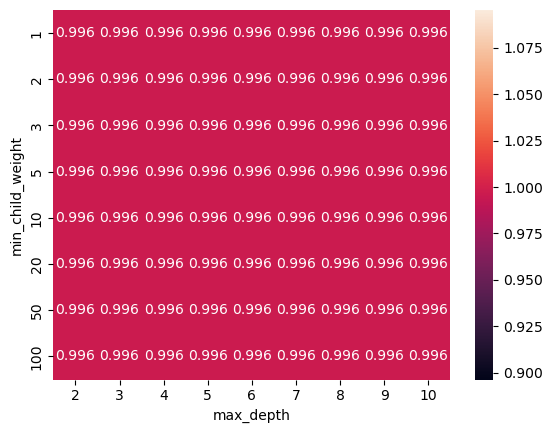

In [154]:
e = 0.1
xgb_scores = []

for w in [1, 2, 3, 5, 10, 20, 50, 100]:
    for d in [2, 3, 4, 5, 6, 7, 8, 9, 10]:
        xgb_params = {
            'eta': e,
            'max_depth': d,
            'min_child_weight': w,
            'objective': 'binary:logistic', 
            'seed': 1,
        }
        xgb_model = xgb.train(xgb_params, dttrain, num_boost_round=175,)
        y_pred = xgb_model.predict(dvval)
        roc_auc_score(y_val, y_pred)
        xgb_scores.append((w, d, auc))




columns = ['min_child_weight', 'max_depth', 'auc']
df_scores = pd.DataFrame(xgb_scores, columns=columns)
df_scores.sort_values(by='auc', ascending=False)



df_scores_pivot = df_scores.pivot(index='min_child_weight', columns='max_depth', values='auc')

sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

## Surprise: The Problem is Not Solved Yet!

Interestingly, the heatmap remains completely red with an AUC of 0.996, meaning the model is still suspiciously perfect even without the CIBIL score.

Let's check the new feature importance breakdown below to find out what is going on.

In [155]:
importance_dict = xgb_model.get_score(importance_type='gain')


df_importance = pd.DataFrame(list(importance_dict.items()), columns=['Feature', 'Importance'])


df_importance = df_importance.sort_values(by='Importance', ascending=False)
print(df_importance.head(5))

                    Feature  Importance
5                _loan_term    7.480016
4              _loan_amount    2.036058
1  _commercial_assets_value    1.763749
9          no_of_dependents    1.702018
2                _education    1.604941


We found another dominant feature: _loan_term. This feature was hidden previously because the CIBIL score was dominating everything

Next, we will drop this feature as well to see if the AUC finally drops to a normal level, or if there is another **hidden reason**.

In [156]:
df_cilib_train = df_train.drop(columns=['_cibil_score', '_loan_term'])
df_cilib_val = df_val.drop(columns=['_cibil_score', '_loan_term'])

dvv = DictVectorizer(sparse=False)

dict1 = df_cilib_train.to_dict(orient='records')
dict2 = df_cilib_val.to_dict(orient='records')

Xi_train = dvv.fit_transform(dict1)
Xi_val = dvv.transform(dict2)

featurs = list(dvv.get_feature_names_out())
dttrain = xgb.DMatrix(Xi_train, label=y_train, feature_names=featurs)
dvval = xgb.DMatrix(Xi_val, label=y_val, feature_names=featurs)

<Axes: xlabel='max_depth', ylabel='min_child_weight'>

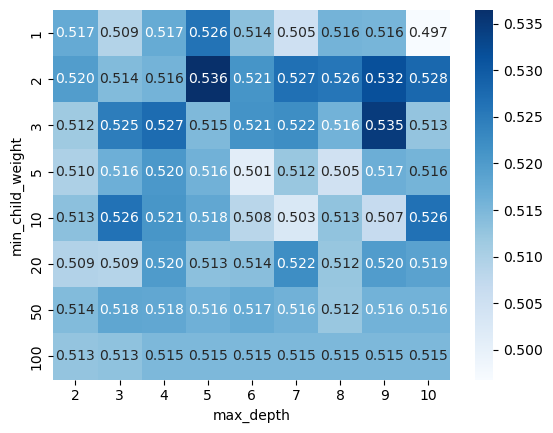

In [157]:

import numpy as np


fresh_xgb_scores = []
e = 0.1


for w in [1, 2, 3, 5, 10, 20, 50, 100]:
    for d in [2, 3, 4, 5, 6, 7, 8, 9, 10]:
        xgb_params = {
            'eta': e,
            'max_depth': d,
            'min_child_weight': w,
            'objective': 'binary:logistic',
            'eval_metric': 'auc',
            'seed': 1,
        }
        
        
        xgb_model = xgb.train(xgb_params, dttrain, num_boost_round=175)
        y_pred = xgb_model.predict(dvval)
        
        
        auc = roc_auc_score(y_val, y_pred)
        fresh_xgb_scores.append((w, d, auc))


columns = ['min_child_weight', 'max_depth', 'auc']
df_fresh_scores = pd.DataFrame(fresh_xgb_scores, columns=columns)


df_fresh_pivot = df_fresh_scores.pivot(index='min_child_weight', columns='max_depth', values='auc')


sns.heatmap(df_fresh_pivot, annot=True, fmt='.3f', cmap='Blues')



## Conclusion: Mystery Solved!

After dropping both dominant features, the validation AUC dropped significantly to around 0.5 - 0.53.

This is a great result because it proves there is no data leakage or errors in our code. The extremely high AUC earlier was purely caused by the heavy dominance of those specific features. Our models and data pipeline are working perfectly, and everything makes sense now!

In [158]:
importance_dict = xgb_model.get_score(importance_type='gain')


df_importance = pd.DataFrame(list(importance_dict.items()), columns=['Feature', 'Importance'])


df_importance = df_importance.sort_values(by='Importance', ascending=False)
print(df_importance.head(5))

                    Feature  Importance
4              _loan_amount    1.715237
8          no_of_dependents    1.707046
2                _education    1.541110
5      _luxury_assets_value    1.441596
1  _commercial_assets_value    1.379421


Looking at this table, the remaining features show very low importance scores and do not tell us much. This explains why our AUC dropped so low. Without the dominant features, the rest of the columns simply do not hold a strong enough signal to make clear predictions.

## **Training the regression models:**

## Data Preparation for Regression Models

We are now preparing our data for the Regression models. While the process is similar to our previous classification setup, there are a few changes here:

1. New Target Variable: Instead of predicting the loan status (0 or 1), our new target is _loan_amount.

2. Filtering the Data: We filtered the dataset using df['_loan_status'] == 1 because we only want to train our models on applicants whose loans were actually approved.

3. Dropped Columns: We dropped _loan_status (since it is now constant) and _loan_amount (since it is our new target variable) to prevent the models from seeing the answers.

4. New Vectorizer: We created a brand new DictVectorizer named dvd just for this regression task, so we don't mix it with our old classification code.

In [159]:
df_reg = df[df['_loan_status'] == 1]


df_reg_full_train, df_reg_test = train_test_split(df_reg, test_size=0.2, random_state=1)
df_reg_train, df_reg_val = train_test_split(df_reg_full_train, test_size=0.25, random_state=1)

df_reg_train = df_reg_train.reset_index(drop=True)
df_reg_val = df_reg_val.reset_index(drop=True)
df_reg_test = df_reg_test.reset_index(drop=True)

t_train = df_reg_train._loan_amount.values
t_val = df_reg_val._loan_amount.values
t_test = df_reg_test._loan_amount.values

columns_to_drop = ['_loan_status', '_loan_amount']
df_reg_train = df_reg_train.drop(columns=columns_to_drop, errors='ignore')
df_reg_val = df_reg_val.drop(columns=columns_to_drop, errors='ignore')
df_reg_test = df_reg_test.drop(columns=columns_to_drop, errors='ignore')



In [160]:
dits = df_reg_train.to_dict(orient='records')
ditss = df_reg_val.to_dict(orient='records')
ditsss = df_reg_test.to_dict(orient='records')

dvd = DictVectorizer(sparse=False)
X2_train = dvd.fit_transform(dits)
X2_val = dvd.transform(ditss)
X2_test = dvd.transform(ditsss)

## 1. Linear regression (Our baseline Model)

We start with Linear Regression because it is our baseline model. it does not need any hyperparameter tuning.

In [161]:
from sklearn.linear_model import LinearRegression

In [162]:
model_lin = LinearRegression()
model_lin.fit(X2_train, t_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


## 2. Decision Tree Regressor

Just like we did with the Decision Tree Classifier, we have two hyperparameters to tune here: max_depth and min_samples_leaf. We will use a heatmap to find the best combination. 

The process is completely the same as before, so there is nothing new to add to the steps.

**The Only Difference: RMSE instead of AUC**

The only main difference between tuning this regression model and our previous classification model is the evaluation metric.

Instead of using AUC, we now use RMSE (Root Mean Squared Error) to evaluate our predictions. In this heatmap, lower values are better.

In [163]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

<Axes: xlabel='max_depth', ylabel='min_samples_leaf'>

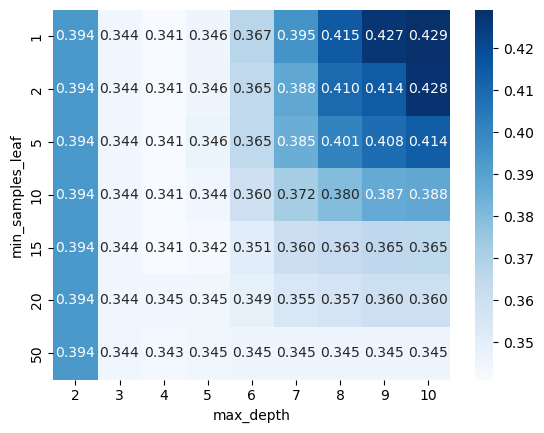

In [164]:
reg_tuning_results = []

for min_samples_leaf in [1, 2, 5, 10, 15, 20, 50]:
    for depth in [2, 3, 4, 5, 6, 7, 8, 9, 10]:
        
        dtr = DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=min_samples_leaf,
            random_state=1
        )
        
        
        dtr.fit(X2_train, t_train)
        t_pred = dtr.predict(X2_val)
        
       
        rmse = np.sqrt(mean_squared_error(t_val, t_pred))
        reg_tuning_results.append((min_samples_leaf, depth, rmse))

df_reg_grid = pd.DataFrame(reg_tuning_results, columns=['min_samples_leaf', 'max_depth', 'rmse'])


df_reg_pivot = df_reg_grid.pivot(index='min_samples_leaf', columns='max_depth', values='rmse')
df_reg_pivot_m = df_reg_pivot / 10000000

sns.heatmap(df_reg_pivot_m, annot=True, fmt='.3f', cmap='Blues')


In [165]:
model_dtr = DecisionTreeRegressor(max_depth=4, min_samples_leaf=15, random_state=1)
model_dtr.fit(X2_train, t_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,15
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,1
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


## 3. Random Forest Regressor

Next, we train a Random Forest Regressor. Just like our previous classification code. The process follows the exact same logic as before, with only one key difference: we are calculating RMSE instead of AUC to evaluate our model's performance.

In [166]:
from sklearn.ensemble import RandomForestRegressor

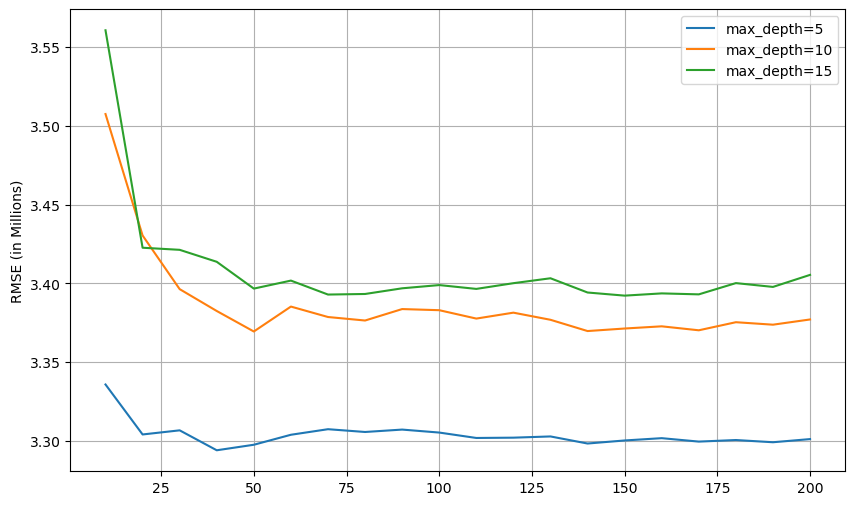

In [167]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error


scores = []


for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        
        rfr = RandomForestRegressor(
            n_estimators=n,
            max_depth=d,
            random_state=1,
            n_jobs=-1
        )
        
        
        rfr.fit(X2_train, t_train)
        t_pred = rfr.predict(X2_val)
        

        rmse = np.sqrt(mean_squared_error(t_val, t_pred)) / 1_000_000
        
        scores.append((d, n, rmse))


columns = ['max_depth', 'n_estimators', 'rmse']
df_scores = pd.DataFrame(scores, columns=columns)


plt.figure(figsize=(10, 6))

for d in [5, 10, 15]:

    df_subset = df_scores[df_scores['max_depth'] == d]
    
    plt.plot(
        df_subset['n_estimators'], 
        df_subset['rmse'], 
        label=f'max_depth={d}'
    )


plt.ylabel('RMSE (in Millions)')
plt.legend()
plt.grid(True)
plt.show()

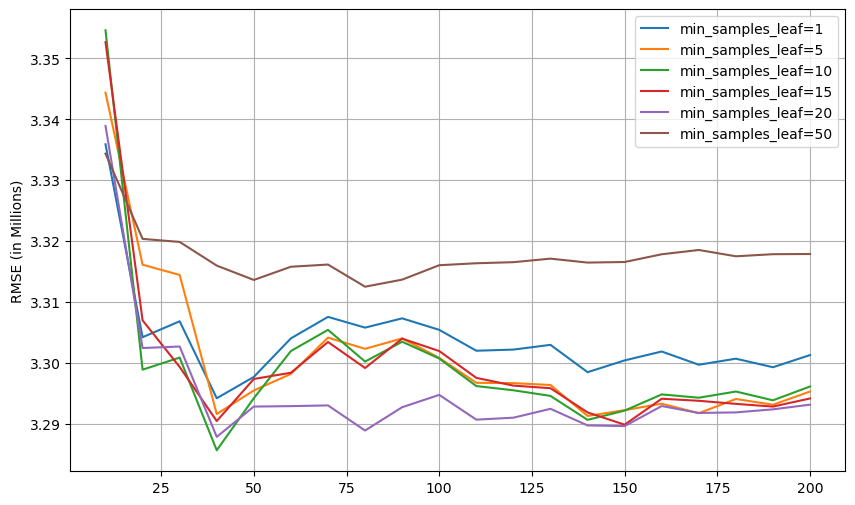

In [168]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

rf_grid_results = []


for leaf in [1, 5, 10, 15, 20, 50]:
    for n in range(10, 201, 10):
        
        
        rf_model = RandomForestRegressor(
            n_estimators=n,
            max_depth=5,
            min_samples_leaf=leaf,
            random_state=1,
            n_jobs=-1
        )
        
        rf_model.fit(X2_train, t_train)
        t_pred = rf_model.predict(X2_val)
        
        
        rmse = np.sqrt(mean_squared_error(t_val, t_pred))
        
        rf_grid_results.append((leaf, n, rmse))

columns = ['min_samples_leaf', 'n_estimators', 'rmse']
df_rf_grid = pd.DataFrame(rf_grid_results, columns=columns)


plt.figure(figsize=(10, 6))




for leaf in [1, 5, 10, 15, 20, 50]:
    
    df_subset = df_rf_grid[df_rf_grid['min_samples_leaf'] == leaf]
    
    
    plt.plot(
        df_subset['n_estimators'], 
        df_subset['rmse'] / 1_000_000, 
        label=f'min_samples_leaf={leaf}',
        
    )



plt.ylabel('RMSE (in Millions)')
plt.legend()
plt.grid(True)
plt.show()

In [169]:
rfr_model = RandomForestRegressor(n_estimators=40, max_depth=5, min_samples_leaf=10, random_state=1)
rfr_model.fit(X2_train, t_train)

,n_estimators,40
,criterion,'squared_error'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## 4. XGBoost Regressor

Finally, we train our last model.

Since we already understand the tuning logic from our previous models, we take a quicker approach here to train and evaluate the model directly. As with the other regression models, we evaluate its final performance using RMSE to see how well it predicts the target value.

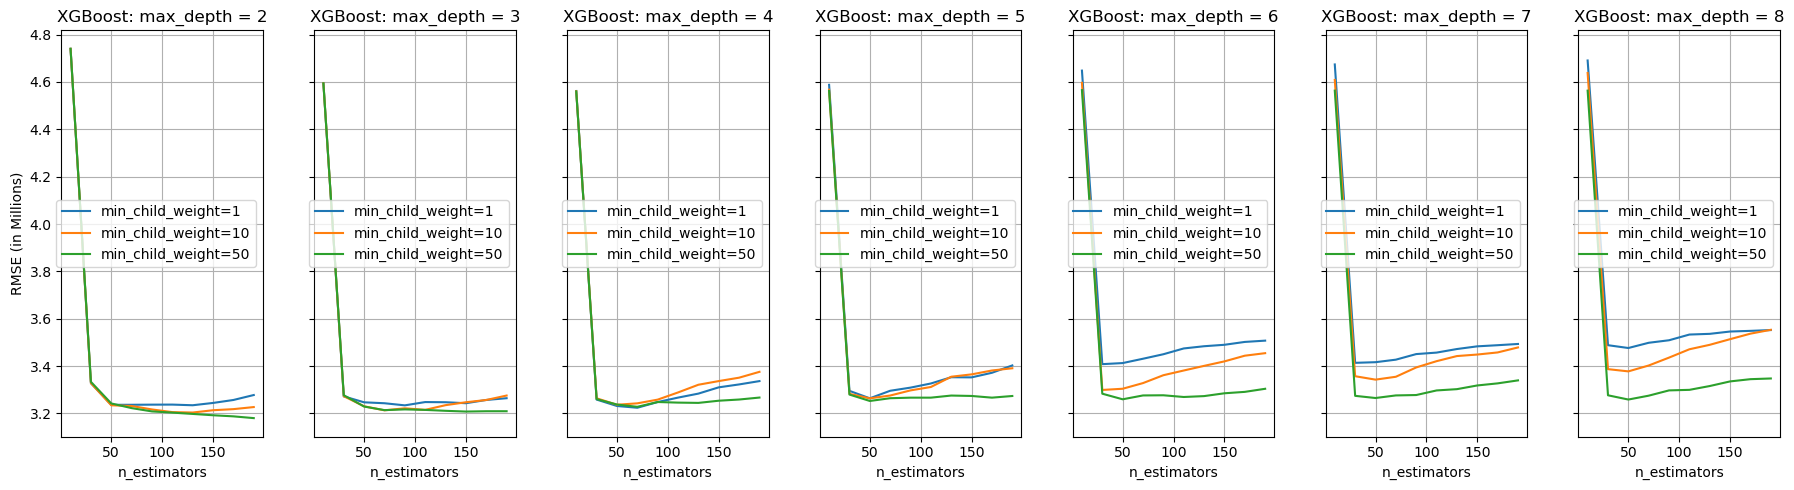

In [170]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import mean_squared_error

xgb_large_results = []



for d in [2, 3, 4, 5, 6, 7, 8]:             
    
    for w in [1, 10, 50]:               
        
        for n in range(10, 201, 20):     
            
            
            model_xgb = xgb.XGBRegressor(
                n_estimators=n,
                learning_rate=0.1,
                min_child_weight=w,
                max_depth=d,            
                
                
                random_state=1,
                n_jobs=-1
            )
            
            
            model_xgb.fit(X2_train, t_train)
            t_pred = model_xgb.predict(X2_val)
            
            
            rmse = np.sqrt(mean_squared_error(t_val, t_pred))
            
            xgb_large_results.append((d, w, n, rmse))


columns = ['max_depth', 'min_child_weight', 'n_estimators', 'rmse']
df_xgb_large = pd.DataFrame(xgb_large_results, columns=columns)



fig, axes = plt.subplots(1, 7, figsize=(18, 5), sharey=True)


for i, d in enumerate([2, 3, 4, 5, 6, 7, 8]):
    ax = axes[i]
    df_max_depth_subset = df_xgb_large[df_xgb_large['max_depth'] == d]
    
    for w in [1, 10, 50]:
        df_w_subset = df_max_depth_subset[df_max_depth_subset['min_child_weight'] == w]
        ax.plot(
            df_w_subset['n_estimators'], 
            df_w_subset['rmse'] / 1_000_000, 
            label=f'min_child_weight={w}',
        )
        
    ax.set_title(f'XGBoost: max_depth = {d}')
    ax.set_xlabel('n_estimators')
    if i == 0:
        ax.set_ylabel('RMSE (in Millions)')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [171]:
final_xgb_model = xgb.XGBRegressor(
    n_estimators=175,
    learning_rate=0.1,
    min_child_weight=50,
    max_depth=2,
    random_state=1
)

In [172]:
final_xgb_model.fit(X2_train, t_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


## **Selecting the Best Models**

Since all our classification models scored a very high and close AUC, we cannot easily pick the winner using AUC alone. instead, we will use **Log Loss** inside our selection loop to choose the most precise model. For our regression models, we will look for the one with the lowest RMSE.

In [173]:
#selecting the best regression model
from sklearn.metrics import log_loss

classification_models = [model_logistic, model_dt, model_rfc, xgb_model_class]

best_loss = float('inf')

best_classifier_model = None


for model in classification_models:
    y_pred_proba = model.predict_proba(X_val)
    current_loss = log_loss(y_val, y_pred_proba)

    
    if current_loss < best_loss:
        best_loss = current_loss
        best_classifier_model = model


print(best_classifier_model)
#selecting the best regression model

regression_models = [model_lin, model_dtr, rfr_model, final_xgb_model]


best_rmse = float('inf')
best_regressor_model = None


for model in regression_models:
    t_pred = model.predict(X2_val)
    rmse_score = np.sqrt(mean_squared_error(t_val, t_pred))
    
    
    if rmse_score < best_rmse:
        best_rmse = rmse_score
        best_regressor_model = model

print(best_regressor_model)




XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.2, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=1, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)
XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric

## Conclusion and Our Final Choice

1. Best Classification Model: XGBoost Classifier won because it got the best (lowest) Log Loss score.

2. Best Regressor Model: XGBoost Regressor won because it got the best (lowest) RMSE score.

## Saving Computer Energy:

Simple models like Logistic Regression or Decision Trees already gave us very high accuracy. We could use them to save computer energy and time. However, since my computer is strong and can handle it, I am choosing XGBoost as our final classification model to get the highest possible results, and the same thing ith the Regression models.

## An Important Note on Feature Importance

At this point, everything is going very well, and we are almost done with our regression task. However, adding this extra information about feature importance is very important for understanding our Regression models.

As we can see in the plot, the Income Amount has a very high importance compared to everything else. This happens because the dataset we selected for this project is highly biased. This matches exactly what we saw earlier in our classification task, where the high bias led to very high AUC scores.

                     Feature  Importance
4              _income_annum    0.876494
6       _luxury_assets_value    0.053867
0          _bank_asset_value    0.023205
1               _cibil_score    0.014992
2   _commercial_assets_value    0.009588
7  _residential_assets_value    0.008974
5                 _loan_term    0.007044
9           no_of_dependents    0.005836
3                 _education    0.000000
8             _self_employed    0.000000


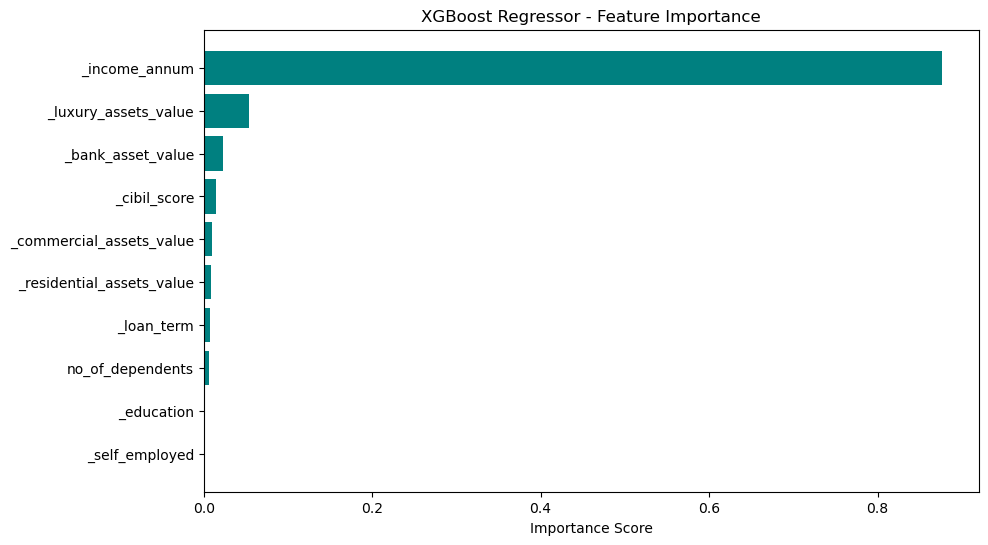

In [174]:


importances = final_xgb_model.feature_importances_

feature_names = dvd.get_feature_names_out()

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(df_importance)

plt.figure(figsize=(10, 6))
plt.barh(df_importance['Feature'][::-1], df_importance['Importance'][::-1], color='teal')
plt.xlabel('Importance Score')
plt.title('XGBoost Regressor - Feature Importance')
plt.show()

## Final Testing on Our Selected Models

Now, we are ready for the final step to finish our notebook! We will test our two winning models on the completely unseen Test Dataset to see how they perform in the real world:

1. XGBoost Classifier: We will check its final Log Loss.

2. XGBoost Regressor: We will calculate its final RMSE.

In [175]:
yy_pred_proba = xgb_model_class.predict_proba(X_test)
log_loss(y_test, yy_pred_proba)

0.0514190047662586

In [176]:
yy_pred = final_xgb_model.predict(X2_test)
np.sqrt(mean_squared_error(t_test, yy_pred))

np.float64(3361109.4719880815)

## **Final Test Results Summary**


* **XGBoost Classifier Log Loss:** `0.0514` (Low error, perfect predictions).

* **XGBoost Regressor RMSE:** `3.36M` (Good error rate, model works correctly).

The project is officially complete and successful!